# AlexNet from Scratch

**Roll No:** 123cs0211  
**Name:** NVSaiRaghava

Labels: 0 = Circle, 1 = Rectangle, 2 = Triangle

## Setup

In [1]:
import numpy as np
import tensorflow as tf
import cv2
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

## Dataset

In [2]:
def generate_synthetic_dataset(num_samples=3000, img_size=227):
    images, labels = [], []

    for _ in range(num_samples):
        label  = np.random.randint(0, 3)
        img    = np.ones((img_size, img_size, 3), dtype=np.uint8) * 200
        color  = tuple(np.random.randint(30, 200, 3).tolist())
        cx, cy = np.random.randint(60, 167), np.random.randint(60, 167)

        if label == 0:          # circle
            r = np.random.randint(30, 60)
            cv2.circle(img, (cx, cy), r, color, -1)

        elif label == 1:        # rectangle
            w = np.random.randint(40, 100)
            h = np.random.randint(40, 100)
            cv2.rectangle(img,
                          (cx - w//2, cy - h//2),
                          (cx + w//2, cy + h//2),
                          color, -1)

        else:                   # triangle
            pts = np.array([
                [cx,      cy - 50],
                [cx - 50, cy + 50],
                [cx + 50, cy + 50]
            ], np.int32)
            cv2.fillPoly(img, [pts], color)

        images.append(img / 255.0)
        labels.append(label)

    images = np.array(images, dtype=np.float32)
    labels = np.array(labels, dtype=np.int32)

    idx = np.random.permutation(len(images))
    images, labels = images[idx], labels[idx]

    split = int(0.8 * num_samples)
    return (images[:split], labels[:split]), (images[split:], labels[split:])


(x_train, y_train), (x_test, y_test) = generate_synthetic_dataset()
CLASS_NAMES = ["Circle", "Rectangle", "Triangle"]

print("x_train:", x_train.shape, x_train.dtype, " y_train:", y_train.shape)
print("x_test :", x_test.shape,  x_test.dtype,  " y_test :", y_test.shape)

x_train: (2400, 227, 227, 3) float32  y_train: (2400,)
x_test : (600, 227, 227, 3) float32  y_test : (600,)


## 1. AlexNet Architecture

LRN layer (custom layer using `tf.nn.local_response_normalization`)

In [3]:
class LocalResponseNormalization(layers.Layer):
    def __init__(self, depth_radius=2, bias=2.0, alpha=1e-4, beta=0.75, **kwargs):
        super().__init__(**kwargs)
        self.depth_radius = depth_radius
        self.bias = bias
        self.alpha = alpha
        self.beta = beta

    def call(self, inputs):
        return tf.nn.local_response_normalization(
            inputs,
            depth_radius=self.depth_radius,
            bias=self.bias,
            alpha=self.alpha,
            beta=self.beta,
        )

Checking that LRN changes the values:

In [4]:
lrn = LocalResponseNormalization()
x = tf.random.uniform((1, 4, 4, 8), 0, 50, seed=SEED)
y = lrn(x)

print("Input  mean:", float(tf.reduce_mean(x)))
print("Output mean:", float(tf.reduce_mean(y)))
print("Mean |input - output|:", float(tf.reduce_mean(tf.abs(x - y))))

Input  mean: 23.997589111328125
Output mean: 12.670791625976562
Mean |input - output|: 11.326799392700195


Model:

In [5]:
inputs = keras.Input(shape=(227, 227, 3), name="input")

# Conv1 -> LRN -> Pool1
x = layers.Conv2D(96, kernel_size=(11, 11), strides=4, activation="relu", name="conv1")(inputs)
x = LocalResponseNormalization(name="lrn1")(x)
x = layers.MaxPooling2D(pool_size=(3, 3), strides=2, name="pool1")(x)

# Conv2 -> LRN -> Pool2
x = layers.Conv2D(256, kernel_size=(5, 5), padding="same", activation="relu", name="conv2")(x)
x = LocalResponseNormalization(name="lrn2")(x)
x = layers.MaxPooling2D(pool_size=(3, 3), strides=2, name="pool2")(x)

# Conv3, Conv4, Conv5 -> Pool3
x = layers.Conv2D(384, kernel_size=(3, 3), padding="same", activation="relu", name="conv3")(x)
x = layers.Conv2D(384, kernel_size=(3, 3), padding="same", activation="relu", name="conv4")(x)
x = layers.Conv2D(256, kernel_size=(3, 3), padding="same", activation="relu", name="conv5")(x)
x = layers.MaxPooling2D(pool_size=(3, 3), strides=2, name="pool3")(x)

# Flatten
x = layers.Flatten(name="flatten")(x)

# FC1 -> Dropout
x = layers.Dense(4096, activation="relu", name="fc1")(x)
x = layers.Dropout(0.5, name="dropout1")(x)

# FC2 -> Dropout
x = layers.Dense(4096, activation="relu", name="fc2")(x)
x = layers.Dropout(0.5, name="dropout2")(x)

# FC3 (output, 3 classes)
outputs = layers.Dense(3, activation="softmax", name="fc3")(x)

model = keras.Model(inputs, outputs, name="AlexNet")
model.summary()

Model: "AlexNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 227, 227, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 55, 55, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lrn1                            │ (None, 55, 55, 96)     │             0 │
│ (LocalResponseNormalization)    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 27, 27, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 27, 27, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lrn2                            │ (None, 27, 27, 256)    │             0 │
│ (LocalResponseNormalization)    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 13, 13, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 13, 13, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 13, 13, 384)    │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv5 (Conv2D)                  │ (None, 13, 13, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │    37,752,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout1 (Dropout)              │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout2 (Dropout)              │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc3 (Dense)                     │ (None, 3)              │        12,291 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 58,293,635 (222.37 MB)

 Trainable params: 58,293,635 (222.37 MB)

 Non-trainable params: 0 (0.00 B)

## 2. Training

Optimizer: Adam (lr = 1e-4). Adam adjusts the learning rate for each parameter, so it trains a deep network like this
without much tuning. SGD with momentum would need a carefully chosen learning rate and schedule. A small learning rate
is used to keep training stable.

In [6]:
EPOCHS = 20
BATCH_SIZE = 32

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

history = model.fit(
    x_train, y_train,
    validation_data=(x_test, y_test),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=2,
)

Epoch 1/20


75/75 - 121s - 2s/step - accuracy: 0.3192 - loss: 1.1008 - val_accuracy: 0.3300 - val_loss: 1.0989


Epoch 2/20


75/75 - 113s - 2s/step - accuracy: 0.3208 - loss: 1.0991 - val_accuracy: 0.3300 - val_loss: 1.0984


Epoch 3/20


...

75/75 - 98s - 1s/step - accuracy: 1.0000 - loss: 3.5939e-05 - val_accuracy: 0.9983 - val_loss: 0.0095


Epoch 19/20


75/75 - 92s - 1s/step - accuracy: 1.0000 - loss: 4.0200e-05 - val_accuracy: 0.9983 - val_loss: 0.0095


Epoch 20/20


75/75 - 92s - 1s/step - accuracy: 1.0000 - loss: 4.1338e-05 - val_accuracy: 0.9983 - val_loss: 0.0082


## 3. Evaluation

Test accuracy and loss

In [7]:
test_loss, test_acc = model.evaluate(x_test, y_test, batch_size=BATCH_SIZE, verbose=0)
print(f"Final test loss    : {test_loss:.4f}")
print(f"Final test accuracy: {test_acc * 100:.2f}%")

Final test loss    : 0.0082
Final test accuracy: 99.83%


Confusion matrix

Confusion matrix (rows = true, cols = predicted):
[[207   0   0]
 [  0 195   0]
 [  1   0 197]]


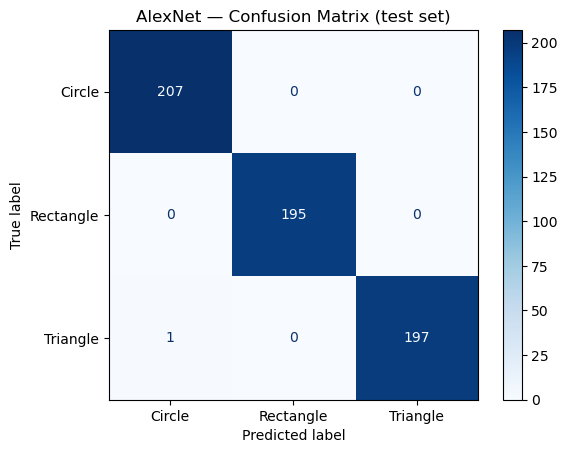

In [8]:
y_prob = model.predict(x_test, batch_size=BATCH_SIZE, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])
print("Confusion matrix (rows = true, cols = predicted):")
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
disp.plot(cmap="Blues", values_format="d")
plt.title("AlexNet — Confusion Matrix (test set)")
plt.show()

Accuracy and loss curves

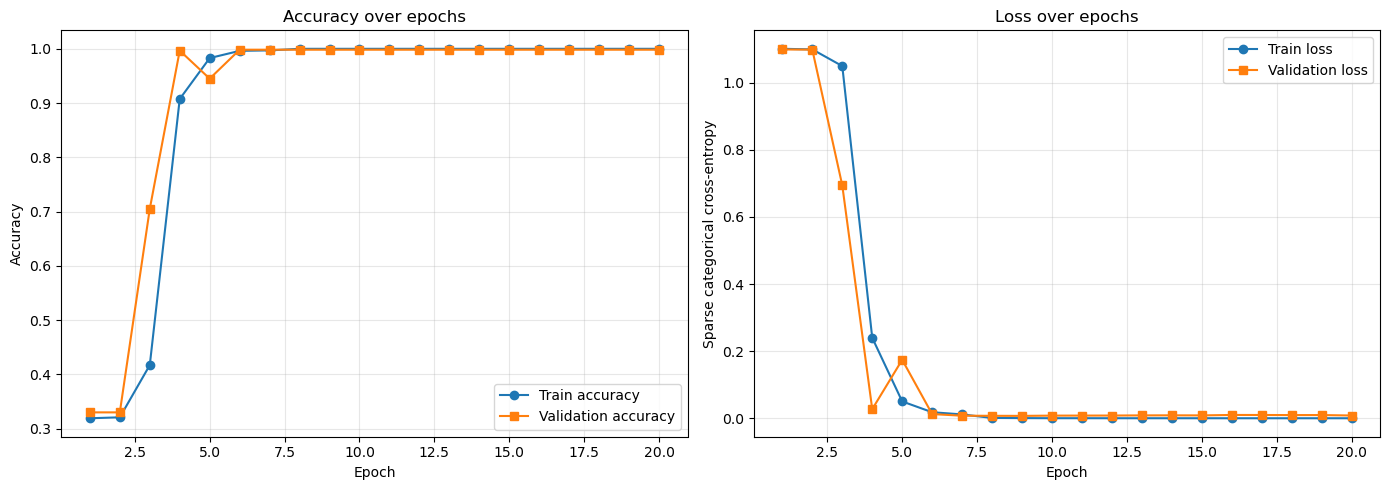

In [9]:
epochs_range = range(1, len(history.history["loss"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(epochs_range, history.history["accuracy"], "o-", label="Train accuracy")
ax1.plot(epochs_range, history.history["val_accuracy"], "s-", label="Validation accuracy")
ax1.set_title("Accuracy over epochs")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Accuracy")
ax1.grid(alpha=0.3)
ax1.legend()

ax2.plot(epochs_range, history.history["loss"], "o-", label="Train loss")
ax2.plot(epochs_range, history.history["val_loss"], "s-", label="Validation loss")
ax2.set_title("Loss over epochs")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Sparse categorical cross-entropy")
ax2.grid(alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

## Observations

- Test accuracy is 99.83% and test loss is 0.0082. Only 1 of the 600 test images is wrong (a triangle predicted as a circle).
- For the first 2 epochs the loss stayed at about 1.099 (ln 3) and accuracy at about 33%, so the model was just guessing.
  Probably because the network is deep, starts from random weights with no batch normalization, and the learning rate is small.
- After that the loss dropped very fast: validation accuracy went from 33% to 99.7% in 2 epochs. The task is easy
  (one shape on a plain background) and the model is very large for 2400 images.
- In epochs 3-4 validation accuracy was higher than training accuracy. This is because dropout is on during training
  and off during validation.
- At epoch 5 validation accuracy dropped to 94.5% for one epoch and then recovered.
- After about epoch 9 training loss keeps going down to almost 0 but validation loss slowly goes up (0.0071 to about 0.0095).
  This is slight overfitting, so training for fewer epochs would have been enough.